# PDAN Part 3
*James Hart*

The dataset used in this project is the The PASCAL Visual Object Classes

Dataset:
https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/

It contains annotated XML files with paired images.

Using a subset of the full dataset, being just the JPEG Files folder and Annotations folder


In [ ]:
# %pip install pandas==2.3.3
# %pip install nltk
# %pip install pyspark
# %pip install numpy
# %pip install scikit-learn
# %pip install tensorflow
# %pip install nbformat
# %pip install plotly
# %pip install PyArrow
# %pip install ElementTree
# %pip install seaborn
# %pip install xgboost
# %pip install PIL

In [4]:
# imports
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
import os
import sys
import importlib.metadata
from pyspark.sql import SparkSession
import csv
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from xml.etree import ElementTree
from pathlib import Path
from pyspark.sql.functions import col, regexp_extract
from PIL import Image
import matplotlib.pyplot as plt
from pyspark.sql import functions as F
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

### Spark Setup

The data loading, inspection, cleaning, exploratory summaries, and feature preparation below use PySpark DataFrames.
Only small aggregated result sets are collected to the driver for visualisation; the source dataset is not converted to pandas.


To setup Spark through PySpark certain requirements have to be met, the correct versioning of Python, PySpark, Java and tensorflow packages. With Spark being very specific about which versions are to be installed to work correctly. 

Specific versions I am running:
- Python 3.13.5
- Java 25.0.4
- Pandas 2.3.3

Due to the lack of native gpu support in tensorflow on windows, everything was run using my Ryzen 5 3600 cpu (10years old), this impacted performance quite heavily, therefore certain cells and parameters have been tuned to optimse the overall performance and speed.

In [5]:
# Configure the Python executables used by PySpark.
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable


In [6]:
# Make sure Pyspark works correctly without erroring out in the background
# version of pandas that runs with Java 25.0.4 and Python 3.13.5
PANDAS_REQUIRED_VERSION = "2.3.3"

try:
    installed_version = importlib.metadata.version("pandas")
    if installed_version != PANDAS_REQUIRED_VERSION:
        raise ImportError(f"Version mismatch: Found {installed_version}")
except importlib.metadata.PackageNotFoundError:
    print(f"Error: pandas is not installed.")
    sys.exit(1)
except ImportError as e:
    print(f"{e}. Run: pip install --upgrade pandas=={PANDAS_REQUIRED_VERSION}")
    sys.exit(1)

import pandas as pd
print(f"Loaded pandas: {pd.__version__}")

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable
print()

Loaded pandas: 2.3.3



In [7]:
# Create a PySpark session with additional memory.
spark = (
    SparkSession.builder
    .appName("PDAN8412 Part 3")
    .config("spark.memory.offHeap.enabled", "true")
    .config("spark.memory.offHeap.size", "10g")
    .config("spark.driver.memory", "4g")
    .config("spark.executor.memory", "4g")
    .config("spark.driver.maxResultSize", "2g")
    .config("spark.sql.execution.arrow.pyspark.enabled", "false")
    .getOrCreate()
)


## Import Dataset

Extract labels from XML sidecar files without making Spark enumerate thousands of small files

In [8]:
# directories of the xml sidecar files and the output CSV file
ANNOTATIONS_DIR = Path("dataset/Annotations")
LABELS_CSV = Path("dataset/annotation_labels.csv")

# Parse the XML annotation files and extract the filename and object labels
def parse_annotation(annotation_path):
    root = ElementTree.parse(annotation_path).getroot()
    filename = root.findtext("filename")
    labels = sorted({name.text for name in root.findall("./object/name") if name.text})
    if not filename or not labels:
        raise ValueError(f"Missing filename or object labels in {annotation_path}")
    return filename, "|".join(labels)

# Use a thread pool to parse the XML files concurrently and write the results to a CSV file
annotation_paths = sorted(ANNOTATIONS_DIR.glob("*.xml"))
if not annotation_paths:
    raise FileNotFoundError(f"No XML annotations found in {ANNOTATIONS_DIR}")

with ThreadPoolExecutor() as executor:
    annotation_rows = list(executor.map(parse_annotation, annotation_paths))

with LABELS_CSV.open("w", newline="", encoding="utf-8") as labels_file:
    writer = csv.writer(labels_file)
    writer.writerow(["filename", "label"])
    writer.writerows(annotation_rows)

print(f"Wrote {len(annotation_rows):,} annotation rows to {LABELS_CSV}")


# AI used to create a reference script to parse the XML files and write the results to a CSV file.
# Then simplified for my use case and improved using threads for performance due to 17,000+ XML files to parse.

Wrote 17,125 annotation rows to dataset\annotation_labels.csv


### Spark

In [9]:
# check if file already exists
if not os.path.exists("dataset/JPEGImages"):
    raise FileNotFoundError("Dataset directory not found")

# Enumerate files with Python to avoid Hadoop's broken Windows NativeIO directory listing.
image_paths = [str(path.resolve()) for path in Path("dataset/JPEGImages").glob("*.jpg")]
image_df = spark.read.format("binaryFile").load(image_paths)

# Extract filename from path as the join key
image_df = image_df.withColumn(
    "filename",
    regexp_extract(col("path"), r"([^/\\]+)\.jpg$", 1)
)

In [10]:
print("Images read:", image_df.count())
image_df.select("path", "length").show(5, truncate=False)

Images read: 17125
+---------------------------------------------------------------------------------------------------------+------+
|path                                                                                                     |length|
+---------------------------------------------------------------------------------------------------------+------+
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_004537.jpg|855251|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2011_006230.jpg|782249|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_001444.jpg|677151|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2009_004444.jpg|373871|
|file:/C:/Users/fanta/OneDrive/Varsity Work/PGDP 2/PDAN8412/Part 3/work/dataset/JPEGImages/2012_003706.jpg|333836|
+------------------------------------------------------------

In [11]:
# Load annotation labels and extract the image stem to match image_df.filename.
annotation_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(str(LABELS_CSV))
    .withColumn(
        "filename",
        regexp_extract(col("filename"), r"([^/\\]+)\.jpg$", 1)
    )
)

# Join image metadata with annotation labels.
image_annotation_df = image_df.join(
    annotation_df,
    on="filename",
    how="inner"
)

print("Joined images:", image_annotation_df.count())
image_annotation_df.select("filename", "label", "length").show(10, truncate=False)

Joined images: 17125
+-----------+------------------------------------+------+
|filename   |label                               |length|
+-----------+------------------------------------+------+
|2009_004537|bottle|chair|diningtable|pottedplant|855251|
|2011_006230|person                              |782249|
|2009_001444|cat                                 |677151|
|2009_004444|bicycle                             |373871|
|2012_003706|person                              |333836|
|2009_002194|bicycle                             |320867|
|2009_003218|cow                                 |304426|
|2008_002866|horse|person                        |300506|
|2012_004075|person                              |294114|
|2008_000647|person                              |291640|
+-----------+------------------------------------+------+
only showing top 10 rows


## EDA


In [12]:
summary_df = image_annotation_df.agg(
    F.countDistinct("filename").alias("images"),
    F.count("label").alias("annotation_rows"),
    F.min("length").alias("smallest_bytes"),
    F.max("length").alias("largest_bytes"),
    F.round(F.avg("length"), 0).alias("average_bytes"),
)
summary_df.show(truncate=False)

+------+---------------+--------------+-------------+-------------+
|images|annotation_rows|smallest_bytes|largest_bytes|average_bytes|
+------+---------------+--------------+-------------+-------------+
|17125 |17125          |7319          |855251       |112235.0     |
+------+---------------+--------------+-------------+-------------+



between 7kb to 850kb

In [13]:
label_counts_df = (
    image_annotation_df
    .select(F.explode(F.split("label", "\\|"))
            .alias("label"))
    .groupBy("label")
    .count()
    .orderBy(F.desc("count"))
)

label_counts_df.show(20, truncate=False)

+-----------+-----+
|label      |count|
+-----------+-----+
|person     |9583 |
|chair      |1366 |
|dog        |1341 |
|car        |1284 |
|cat        |1128 |
|bottle     |812  |
|bird       |811  |
|sofa       |742  |
|aeroplane  |716  |
|diningtable|691  |
|tvmonitor  |645  |
|pottedplant|613  |
|bicycle    |603  |
|train      |589  |
|motorbike  |575  |
|boat       |549  |
|horse      |526  |
|bus        |467  |
|sheep      |357  |
|cow        |340  |
+-----------+-----+



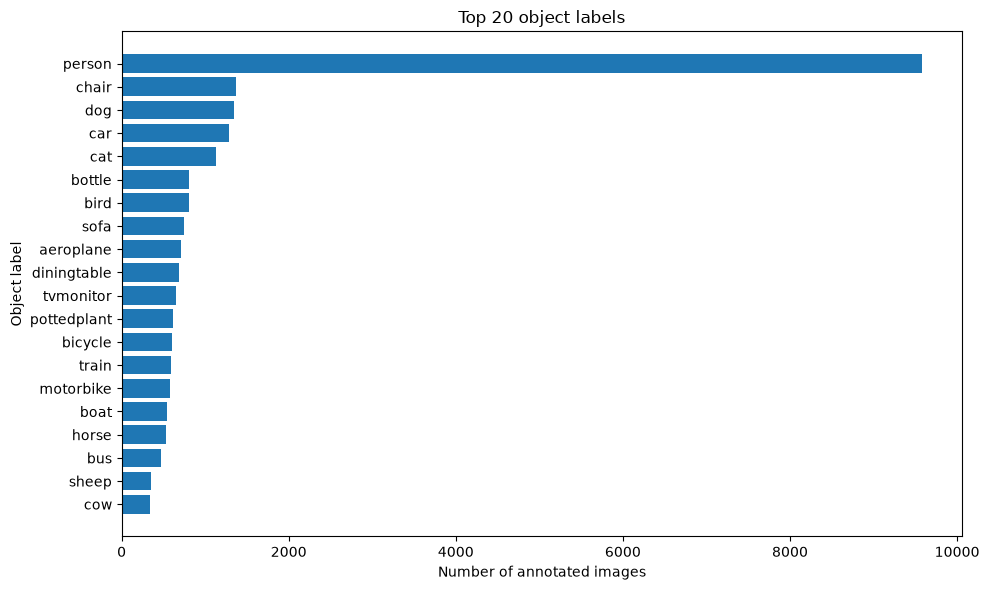

In [14]:
top_labels = label_counts_df.limit(20).toPandas()
plt.figure(figsize=(10, 6))
plt.barh(top_labels["label"][::-1], top_labels["count"][::-1])
plt.xlabel("Number of annotated images")
plt.ylabel("Object label")
plt.title("Top 20 object labels")
plt.tight_layout()
plt.show()

the class imbalance is quite severe, would require class weights and tuning

In [15]:
quality_df = image_annotation_df.select(
    F.sum(F.col("label").isNull().cast("int")).alias("missing_labels"),
    F.sum((F.col("length") <= 0).cast("int")).alias("non_positive_file_sizes"),
)
quality_df.show()

+--------------+-----------------------+
|missing_labels|non_positive_file_sizes|
+--------------+-----------------------+
|             0|                      0|
+--------------+-----------------------+



In [16]:
sample_size = 120

# Randomly select images 
sampled_filenames = [
    row["filename"]
    for row in (
        image_annotation_df
        .select("filename")
        .distinct()
        .orderBy(F.rand())
        .limit(sample_size)
        .collect()
    )
]

image_path_by_filename = {
    Path(path).stem: path
    for path in image_paths
}

image_properties = []

for filename in sampled_filenames:
    image_path = image_path_by_filename.get(filename)

    if image_path is None:
        continue

    with Image.open(image_path) as image:
        image_properties.append({
            "filename": filename,
            "width": image.width,
            "height": image.height,
            "channels": len(image.getbands()),
            "mode": image.mode,
        })

image_properties_df = pd.DataFrame(image_properties)
display(image_properties_df)

,filename,width,height,channels,mode
0,2012_004186,302,500,3,RGB
1,2008_007664,500,341,3,RGB
2,2012_001828,500,375,3,RGB
3,2008_006386,375,500,3,RGB
4,2009_003172,500,385,3,RGB
...,...,...,...,...,...
115,2010_000432,500,333,3,RGB
116,2012_002168,500,402,3,RGB
117,2009_003594,375,500,3,RGB
118,2010_005458,333,500,3,RGB


In [17]:
# stats of subset
image_properties_df.describe()

,width,height,channels
count,120.000000,120.000000,120.0
mean,457.433333,398.766667,3.0
std,72.400118,66.157532,0.0
min,212.000000,281.000000,3.0
25%,375.000000,355.750000,3.0
50%,500.000000,375.000000,3.0
75%,500.000000,491.000000,3.0
max,500.000000,500.000000,3.0


within expected. The width is generally 500 and height is generally 375

## Data preparation
converts them to a binary target: an image is positive when its annotation includes person.

In [18]:
# variables used for training consistency
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

# build the label dataset
labels_df = pd.read_csv(LABELS_CSV)
labels_df["path"] = labels_df["filename"].map(
    {Path(path).name: path for path in image_paths}
)
# drop rows with missing paths
labels_df = labels_df.dropna(subset=["path"]).copy()
labels_df["human"] = labels_df["label"].str.split("|").apply(
    lambda labels: int("person" in labels)
)
# drop duplicates 
labels_df = labels_df[["path", "human"]].drop_duplicates("path")

# Splitting
train_df, temp_df = train_test_split(
    labels_df, test_size=0.30, random_state=42, stratify=labels_df["human"]
)
validation_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df["human"]
)
#Check the number of samples in each split 
print({name: len(frame) for name, frame in {
    "train": train_df, "validation": validation_df, "test": test_df
}.items()})
print(labels_df["human"].value_counts(normalize=True).sort_index())
# AI used to help test and improve data preparation to prevent data leakage

{'train': 11987, 'validation': 2569, 'test': 2569}
human
0    0.440409
1    0.559591
Name: proportion, dtype: float64


Images are decoded as RGB, resized to a common shape, and augmented only during training.


In [19]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    return image, tf.cast(label, tf.float32)


def make_dataset(frame, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (frame["path"].to_numpy(), frame["human"].to_numpy())
    )
    if shuffle:
        dataset = dataset.shuffle(len(frame), seed=42)
    return dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, shuffle=True)
validation_ds = make_dataset(validation_df)
test_ds = make_dataset(test_df)


## Baseline Model

A small CNN learns image features and outputs the probability that a person is present.


In [20]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.Rescaling(1 / 255.0),
    tf.keras.layers.Conv2D(16, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.20),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

counts = train_df["human"].value_counts()
class_weight = (len(train_df) / (2 * counts)).to_dict()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")],
)

baseline_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=30,
    class_weight=class_weight,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_auc", mode="max", patience=2, restore_best_weights=True
    )],
)

Epoch 1/30


c:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 52ms/step - accuracy: 0.5413 - auc: 0.5588 - loss: 0.6885 - val_accuracy: 0.5512 - val_auc: 0.6074 - val_loss: 0.6860
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 48ms/step - accuracy: 0.5735 - auc: 0.6002 - loss: 0.6789 - val_accuracy: 0.6275 - val_auc: 0.6483 - val_loss: 0.6581
Epoch 3/30
374/375 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5914 - auc: 0.6269 - loss: 0.6700

KeyboardInterrupt: 

In [ ]:
# model_dir = Path("models")
# model_dir.mkdir(exist_ok=True)

# model_path = model_dir / "human_classifier.keras"
# model.save(model_path)

# print(f"Model saved to: {model_path.resolve()}")

### Evaluation

final accuracy, AUC, precision, recall, and the confusion matrix.


Test loss: 0.631
Test accuracy: 0.647
Test AUC: 0.705
              precision    recall  f1-score   support

   no person       0.58      0.73      0.64      1132
      person       0.73      0.58      0.65      1437

    accuracy                           0.65      2569
   macro avg       0.66      0.66      0.65      2569
weighted avg       0.66      0.65      0.65      2569



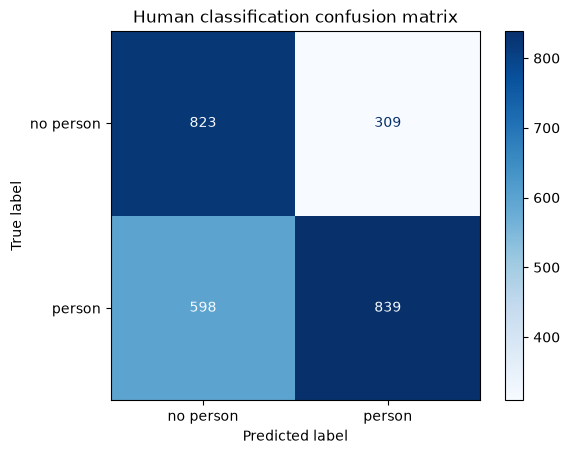

In [ ]:
test_loss, test_accuracy, test_auc = model.evaluate(test_ds, verbose=0)
test_probabilities = model.predict(test_ds, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels = test_df["human"].to_numpy()

print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test AUC: {test_auc:.3f}")
print(classification_report(
    test_labels, test_predictions, target_names=["no person", "person"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(test_labels, test_predictions),
    display_labels=["no person", "person"],
).plot(cmap="Blues")
plt.title("Human classification confusion matrix")
plt.show()


decent model, performs adequaetly as test model. No person precision and person recall could use more work. AUC is decent at .70

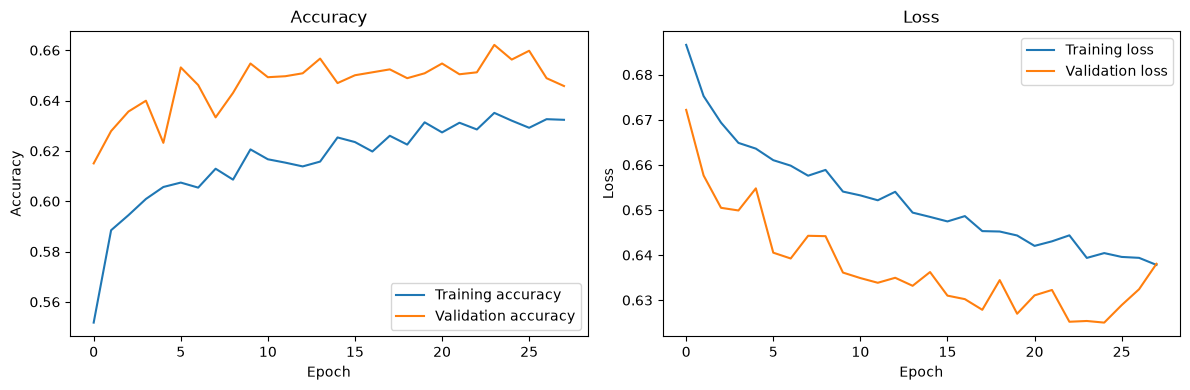

In [ ]:
# training and validation accuracy and loss
training_history = baseline_history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(training_history["accuracy"], label="Training accuracy")
axes[0].plot(training_history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(training_history["loss"], label="Training loss")
axes[1].plot(training_history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

shows marginal improvements past the 5 and 10 epoch

## Improved Model

In [ ]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMAGE_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),   # cheap, keep
    tf.keras.layers.Rescaling(1/255.0),

    tf.keras.layers.Conv2D(24, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),             

    tf.keras.layers.Conv2D(48, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(48, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(96, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Conv2D(96, 3, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(96, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

counts = train_df["human"].value_counts()
class_weight = (len(train_df) / (2 * counts)).to_dict()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc"),
             tf.keras.metrics.Precision(), tf.keras.metrics.Recall()],
)

improved_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=50,
    class_weight=class_weight,
    callbacks=[
    tf.keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True,
                                     monitor="val_auc", mode="max"),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3,
                                         monitor="val_loss", min_lr=1e-6),
        ],
)

Epoch 1/50


c:\Users\fanta\OneDrive\Varsity Work\PGDP 2\PDAN8412\Part 3\work\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


375/375 ━━━━━━━━━━━━━━━━━━━━ 125s 322ms/step - accuracy: 0.6087 - auc: 0.6430 - loss: 0.6662 - precision_1: 0.6647 - recall_1: 0.6070 - val_accuracy: 0.4889 - val_auc: 0.7120 - val_loss: 0.7816 - val_precision_1: 0.7990 - val_recall_1: 0.1161 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 117s 313ms/step - accuracy: 0.6552 - auc: 0.7074 - loss: 0.6286 - precision_1: 0.7076 - recall_1: 0.6543 - val_accuracy: 0.6824 - val_auc: 0.7663 - val_loss: 0.5908 - val_precision_1: 0.6615 - val_recall_1: 0.8860 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 114s 304ms/step - accuracy: 0.6751 - auc: 0.7324 - loss: 0.6082 - precision_1: 0.7267 - recall_1: 0.6720 - val_accuracy: 0.7077 - val_auc: 0.7784 - val_loss: 0.5617 - val_precision_1: 0.7400 - val_recall_1: 0.7364 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 116s 310ms/step - accuracy: 0.6893 - auc: 0.7539 - loss: 0.5911 - precision_1: 0.7424 - recall_1: 0.6813 - val_accuracy: 0.6294 - val_auc

In [ ]:
# model_dir = Path("models")
# model_dir.mkdir(exist_ok=True)

# model_path = model_dir / "human_classifier_improved.keras"
# model.save(model_path)

# print(f"Model saved to: {model_path.resolve()}")

### Evaluation

Test loss: 0.399
Test accuracy: 0.818
Test AUC: 0.898
              precision    recall  f1-score   support

   no person       0.78      0.81      0.80      1132
      person       0.85      0.82      0.83      1437

    accuracy                           0.82      2569
   macro avg       0.82      0.82      0.82      2569
weighted avg       0.82      0.82      0.82      2569



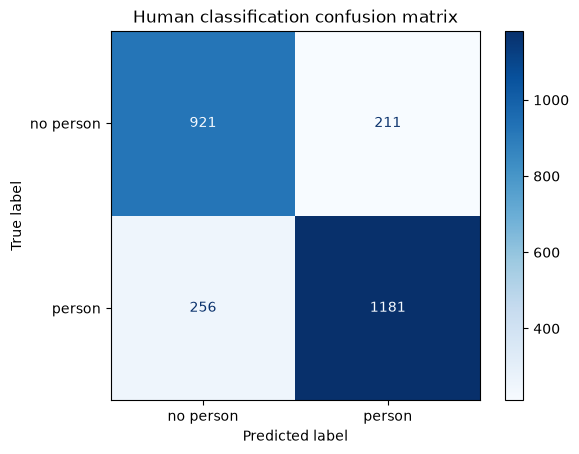

In [ ]:
improved_evaluation = model.evaluate(test_ds, verbose=0, return_dict=True)

test_loss = improved_evaluation["loss"]
test_accuracy = improved_evaluation["accuracy"]
test_auc = improved_evaluation["auc"]
test_probabilities = model.predict(test_ds, verbose=0).ravel()
test_predictions = (test_probabilities >= 0.5).astype(int)
test_labels = test_df["human"].to_numpy()

print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test AUC: {test_auc:.3f}")
print(classification_report(
    test_labels, test_predictions, target_names=["no person", "person"],
    zero_division=0
))

ConfusionMatrixDisplay(
    confusion_matrix(test_labels, test_predictions),
    display_labels=["no person", "person"],
).plot(cmap="Blues")
plt.title("Human classification confusion matrix")
plt.show()



much better results across all metrics

recall is really strong and person precision is the best

AUC is extremly high now, indicating good seperation between classes.

In [ ]:
# training and validation accuracy and loss
training_history = improved_history.history

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(training_history["accuracy"], label="Training accuracy")
axes[0].plot(training_history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(training_history["loss"], label="Training loss")
axes[1].plot(training_history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

validation across both metrics are unstable, could be learning rate too high

## Comparison

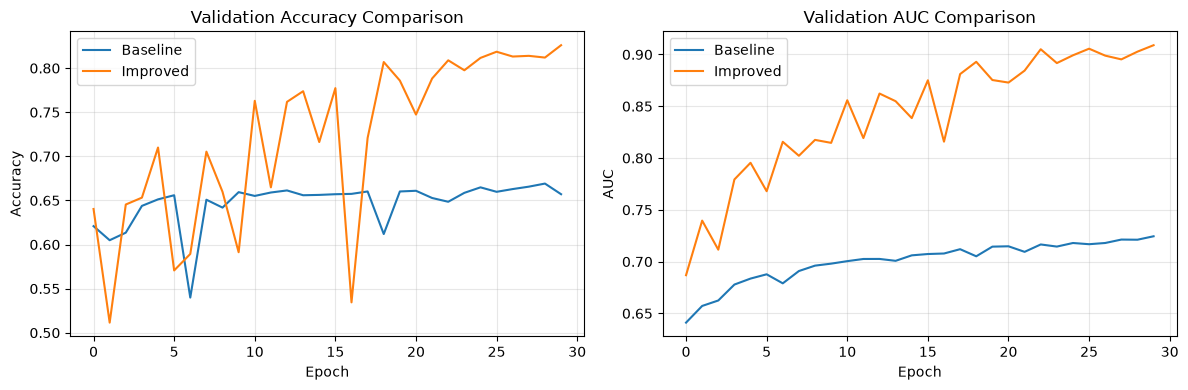

In [ ]:
# comparison of baseline and improved training 

baseline_metrics = baseline_history.history
improved_metrics = (
    improved_history.history
    if hasattr(improved_history, "history")
    else improved_history
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for metrics, name in [
    (baseline_metrics, "Baseline"),
    (improved_metrics, "Improved"),
]:
    axes[0].plot(metrics["val_accuracy"], label=name)
    axes[1].plot(metrics["val_auc"], label=name)

axes[0].set_title("Validation Accuracy Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation AUC Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

spiky beginnings which levels out for the improved model

baseline model stabilises quite soon and shows marginal improvements over the epochs

In [ ]:
import cv2
from PIL import ImageGrab
# section used of the screen, which connects to my phone camera stream
SCREEN_REGION = (100, 100, 740, 580)

# loop
while True:
    # grabs screenshots
    screenshot = ImageGrab.grab(bbox=SCREEN_REGION, all_screens=True)
    frame = np.array(screenshot)

    # resize for model input
    resized = cv2.resize(frame, IMAGE_SIZE)
    # output
    probability = float(model.predict(resized[None, ...], verbose=0)[0][0])

    # simple threshold
    label = "Person" if probability >= 0.5 else "No person"
    confidence = probability if probability >= 0.5 else 1 - probability
    # red and green
    colour = (0, 255, 0) if label == "Person" else (0, 0, 255)

    # display the frame with label and confidence
    display_frame = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    cv2.putText(
        display_frame,
        f"{label}: {confidence:.1%}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        1,
        colour,
        2,
    )
    # show the frame
    cv2.imshow("Human classifier", display_frame)


displays an image frame of the live screen, which then i can show images to test the model live